In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(
    f"mysql+pymysql://{os.getenv('MYSQL_USER')}:{quote_plus(os.getenv('MYSQL_PASSWORD'))}"
    f"@{os.getenv('MYSQL_HOST')}/{os.getenv('MYSQL_DB')}"
)
df = pd.read_sql("SELECT * FROM customers_raw", engine)
df.shape

(7043, 21)

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges"]]

11


,customerID,tenure,MonthlyCharges
488,4472-LVYGI,0,52.55
753,3115-CZMZD,0,20.25
936,5709-LVOEQ,0,80.85
1082,4367-NUYAO,0,25.75
1340,1371-DWPAZ,0,56.05
3331,7644-OMVMY,0,19.85
3826,3213-VVOLG,0,25.35
4380,2520-SGTTA,0,20.00
5218,2923-ARZLG,0,19.70
6670,4075-WKNIU,0,73.35


In [3]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [4]:
print(df.duplicated().sum(), df["customerID"].duplicated().sum())
print(df.isna().sum().sum())

0 0
0


In [5]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [6]:
for col in df.select_dtypes("object").columns.drop("customerID"):
    print(col, df[col].unique())

gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <StringArray>
['Month-to-month', 'One year', 'Two year']
Le

C:\Users\Bharath\AppData\Local\Temp\ipykernel_20364\4180034576.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object").columns.drop("customerID"):


In [7]:
df.to_sql("customers_clean", engine, if_exists="replace", index=False)

7043

In [8]:
cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies"]
for c in cols:
    df[c] = df[c].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

df.to_sql("customers_clean", engine, if_exists="replace", index=False)

7043

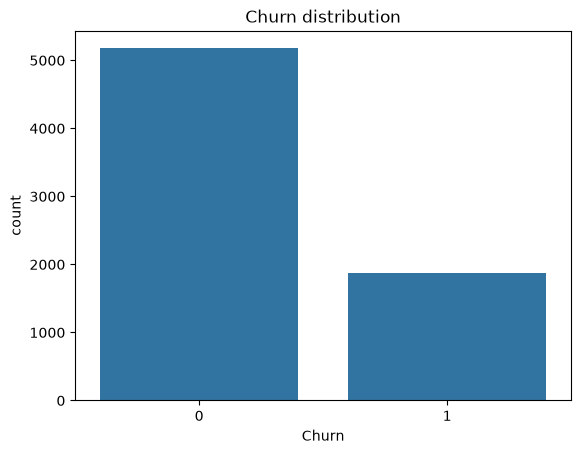

In [9]:
sns.countplot(data=df, x="Churn")
plt.title("Churn distribution")
plt.show()

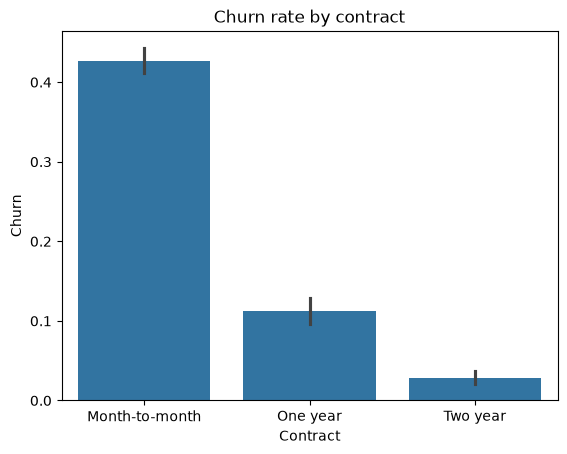

In [10]:
sns.barplot(data=df, x="Contract", y="Churn")
plt.title("Churn rate by contract")
plt.show()

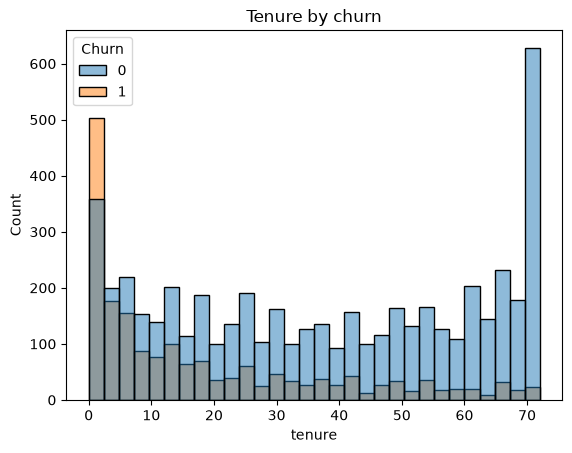

In [11]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure by churn")
plt.show()